<a href="https://colab.research.google.com/github/jioh-shin/econ5200-PS03/blob/main/ps3_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.

## Setup

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [53]:
import io
import re
import urllib.request
import zipfile
import pandas as pd

raw = urllib.request.urlopen("https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d", z.read("codebook").decode("latin-1"), re.M)

ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None, names=names, na_values=["."])

ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

means_by_state = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()

nj = means_by_state.loc[1]
pa = means_by_state.loc[0]

did = (nj.fte_after - nj.fte_before) - (pa.fte_after - pa.fte_before)

print(means_by_state)
print(f"DiD estimate: {did:.2f}")

assert round(did, 2) == 2.75
print("Step 1.1 checkpoint PASSED")



       fte_before  fte_after
STATE                       
0          23.331     21.166
1          20.439     21.027
DiD estimate: 2.75
Step 1.1 checkpoint PASSED


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [54]:
import statsmodels.formula.api as smf

# Reshape the data into long format
before = ck[["STATE", "fte_before"]].copy()
before.columns = ["treated", "fte"]
before["post"] = 0

after = ck[["STATE", "fte_after"]].copy()
after.columns = ["treated", "fte"]
after["post"] = 1

long_df = pd.concat([before, after], ignore_index=True)
long_df = long_df.dropna(subset=["fte"])

# Run the DiD regression
model = smf.ols("fte ~ treated + post + treated:post", data=long_df).fit()
print(model.summary())

# Extract the DiD estimate
reg_did = model.params["treated:post"]

print(f"\nRegression DiD estimate: {reg_did:.2f}")


                            OLS Regression Results                            
Dep. Variable:                    fte   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.964
Date:                Fri, 06 Nov 2026   Prob (F-statistic):              0.118
Time:                        02:14:44   Log-Likelihood:                -2904.2
No. Observations:                 794   AIC:                             5816.
Df Residuals:                     790   BIC:                             5835.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       23.3312      1.072     21.767   

*Your answer here.*
The coefficient on treated represents the baseline employment difference between New Jersey and Pennsylvania before the minimum wage increase.
The coefficient on post represents the change in employment from before to after the policy in Pennsylvania, the control group.
Neither coefficient is causal because the first captures pre-existing differences between states, while the second may reflect general time trends or other factors.
The interaction coefficient treated:post is the DiD estimate of 2.75 FTE. Under the parallel trends assumption and other identification conditions, it can be interpreted as the causal effect of the minimum wage increase.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [55]:

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# Step 2.1: Simulate the county-year panel
rng = np.random.default_rng(42)

n_boards = 8
counties_per_board = 5
n_years = 12

# Board-level adoption years
adoption_years = {0: 2, 1: 2, 2: 2, 3: 3, 4: 4, 5: 5, 6: 5, 7: np.inf}

# Treatment effect grows with exposure
effect_growth = 1.5

# Shared board-year shock
board_shock_sd = 0.25
board_shocks = {(b, t): rng.normal(0, board_shock_sd) for b in range(n_boards) for t in range(n_years)}

# County fixed effects
county_fe = rng.normal(0, 2, 40)

rows = []

for county in range(40):
    board = county // 5
    cohort = adoption_years[board]

    for year in range(n_years):
        treated = int(year >= cohort)
        exposure = (max(0, year - cohort + 1) if np.isfinite(cohort) else 0)
        growth_rate = 3.0 if cohort == 2 else 1.0
        true_effect = growth_rate * exposure
        outcome = (20 + county_fe[county] + 0.3 * year + board_shocks[(board, year)] + rng.normal(0, 0.2) + true_effect)
        rows.append({"county": county, "board": board, "year": year, "cohort": cohort, "treated": treated, "exposure": exposure, "true_effect": true_effect, "outcome": outcome})

panel = pd.DataFrame(rows)

print("Panel shape:", panel.shape)
print("Counties:", panel["county"].nunique())
print("Boards:", panel["board"].nunique())
print("Years:", panel["year"].nunique())

assert panel.shape[0] == 480
assert panel["county"].nunique() == 40
assert panel["board"].nunique() == 8

# True average treatment effect on the treated
true_att = panel.loc[panel["treated"] == 1, "true_effect"].mean()

# Agency's TWFE regression
twfe_model = smf.ols("outcome ~ treated + C(county) + C(year)", data=panel).fit()

twfe_estimate = twfe_model.params["treated"]

print("\nTrue ATT:", round(true_att, 3))
print("TWFE estimate:", round(twfe_estimate, 3))
print("TWFE bias:", round(twfe_estimate - true_att, 3))

print("\nTrue effect range:")
print(panel.loc[panel["treated"] == 1, "true_effect"].agg(["min", "max"]))


Panel shape: (480, 8)
Counties: 40
Boards: 8
Years: 12

True ATT: 10.361
TWFE estimate: -0.644
TWFE bias: -11.005

True effect range:
min     1.0
max    30.0
Name: true_effect, dtype: float64


*Your answer here.*
I simulated a balanced panel of 40 counties across 8 regional boards over 12 years. Treatment adoption occurs at the board level over four years, with two boards remaining untreated. The treatment effect increases with exposure, and counties within the same board share a board-year shock.

The true ATT is approximately 6.533, while the TWFE estimate is approximately 3.803. The TWFE estimate understates the true average treatment effect by about 2.730. This difference illustrates how TWFE can produce misleading estimates under staggered treatment adoption and heterogeneous treatment effects.

### Step 2.2: Decompose it (15 pts)

In [56]:
# Step 2.2: Full Goodman-Bacon decomposition

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# Residualize treatment against county and year FE
def treatment_residual(df):
    d = df["treated"].astype(float)

    return (d - df.groupby("county")["treated"].transform("mean") - df.groupby("year")["treated"].transform("mean") + d.mean())

n_total = panel["county"].nunique()
t_total = panel["year"].nunique()

cohorts = sorted(panel["cohort"].unique())
comparisons = []

# Each pair of adoption cohorts
for i, early in enumerate(cohorts):
    for late in cohorts[i + 1:]:

        pair = panel[panel["cohort"].isin([early, late])].copy()

        if np.isinf(late):
            windows = [("never-treated", pair)]
        else:
            windows = [("clean", pair[pair["year"] < late].copy()), ("forbidden", pair[pair["year"] >= early].copy())]

        for comparison_type, sub in windows:

            # Estimate the two-by-two DiD
            fit = smf.ols("outcome ~ treated + C(county) + C(year)", data=sub).fit()

            estimate = fit.params["treated"]

            # Goodman-Bacon design weight
            residual = treatment_residual(sub)
            n_sub = sub["county"].nunique()
            t_sub = sub["year"].nunique()

            weight_raw = ((residual ** 2).sum() * (n_sub / n_total) * (t_sub / t_total))

            comparisons.append({"treated": early if comparison_type != "forbidden" else late, "control": late if comparison_type != "forbidden" else early, "type": comparison_type, "estimate": estimate, "weight_raw": weight_raw})

bacon = pd.DataFrame(comparisons)

# Normalize weights to sum to one
bacon["weight"] = (bacon["weight_raw"] / bacon["weight_raw"].sum())

# Reconstruct TWFE
bacon_twfe = (bacon["estimate"] * bacon["weight"]).sum()

# Weight share of forbidden comparisons
forbidden_weight = bacon.loc[bacon["type"] == "forbidden", "weight"].sum()

print("Goodman-Bacon decomposition:")
print(bacon[["treated", "control", "type", "estimate", "weight"]].round(4).to_string(index=False))

print("\nWeight sum:", round(bacon["weight"].sum(), 6))
print("Reconstructed TWFE:", round(bacon_twfe, 3))
print("Original TWFE:", round(twfe_estimate, 3))

print("Forbidden comparison weight:", f"{forbidden_weight:.2%}")

# Validation
assert np.isclose(bacon["weight"].sum(), 1.0)
assert np.isclose(bacon_twfe, twfe_estimate, atol=1e-8)

print("\nStep 2.2 decomposition PASSED")


Goodman-Bacon decomposition:
 treated  control          type  estimate  weight
     2.0      3.0         clean     3.104   0.012
     3.0      2.0     forbidden    -9.641   0.052
     2.0      4.0         clean     4.472   0.023
     4.0      2.0     forbidden   -10.665   0.093
     2.0      5.0         clean     5.809   0.070
     5.0      2.0     forbidden   -11.036   0.244
     2.0      inf never-treated    16.473   0.116
     3.0      4.0         clean     1.112   0.006
     4.0      3.0     forbidden    -0.283   0.015
     3.0      5.0         clean     1.581   0.023
     5.0      3.0     forbidden    -0.493   0.054
     3.0      inf never-treated     5.141   0.052
     4.0      5.0         clean     0.338   0.015
     5.0      4.0     forbidden    -0.424   0.027
     4.0      inf never-treated     4.234   0.062
     5.0      inf never-treated     4.038   0.135

Weight sum: 1.0
Reconstructed TWFE: -0.644
Original TWFE: -0.644
Forbidden comparison weight: 48.55%

Step 2.2 decomposi

*Your answer here.*
The Goodman-Bacon decomposition shows that the TWFE estimate is affected by forbidden comparisons, where already-treated counties are used as controls.
The clean comparison gives an estimate of 5.809, while the forbidden comparison gives -11.036. The TWFE estimate is -0.644, even though all true treatment effects are positive, ranging from 1 to 30.
The decomposition reconstructs the original TWFE estimate of -0.644. The current weighting calculation assigns 48.55% of the total weight to forbidden comparisons.
This shows that TWFE can produce a misleading estimate under staggered adoption when treatment effects grow over time. Already-treated counties are not appropriate controls because their treatment effects continue to change.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [57]:

# Step 3.1: Clean cohort-time ATT estimation

import numpy as np
import pandas as pd

cohorts = sorted(panel.loc[np.isfinite(panel["cohort"]), "cohort"].unique())
results = []
for g in cohorts:

    # Baseline: one year before treatment
    baseline = int(g) - 1

    # Counties first treated in year g
    treated_counties = panel.loc[panel["cohort"] == g, "county"].unique()
    for t in range(int(g), 12):
        # Controls: never-treated or not-yet-treated
        control_counties = panel.loc[panel["cohort"] > t, "county"].unique()
        # Baseline outcomes
        treated_pre = panel.loc[(panel["county"].isin(treated_counties)) & (panel["year"] == baseline), "outcome"].mean()
        control_pre = panel.loc[(panel["county"].isin(control_counties)) & (panel["year"] == baseline), "outcome"].mean()
        # Current outcomes
        treated_post = panel.loc[(panel["county"].isin(treated_counties)) & (panel["year"] == t), "outcome"].mean()
        control_post = panel.loc[(panel["county"].isin(control_counties)) & (panel["year"] == t), "outcome"].mean()

        # Clean DiD estimate for cohort g at time t
        att_gt = ((treated_post - treated_pre) - (control_post - control_pre))

        # True effect for this cohort-period
        true_gt = panel.loc[(panel["cohort"] == g) & (panel["year"] == t), "true_effect"].mean()
        results.append({"cohort": g, "year": t, "att_gt": att_gt, "true_att_gt": true_gt, "n_treated": len(treated_counties)})

att_table = pd.DataFrame(results)

# Aggregate using the number of treated county-years
clean_att = np.average(att_table["att_gt"], weights=att_table["n_treated"])

# Compare with truth and TWFE
print("True ATT:", round(true_att, 3))
print("TWFE estimate:", round(twfe_estimate, 3))
print("Clean ATT:", round(clean_att, 3))

print("\nTWFE bias:", round(twfe_estimate - true_att, 3))
print("Clean ATT error:", round(clean_att - true_att, 3))

print("\nCohort-period estimates:")
print(att_table.round(3).to_string(index=False))

# Validate coverage and treatment assignment
assert len(att_table) > 0
assert att_table["att_gt"].notna().all()
assert np.isclose(np.average(att_table["true_att_gt"], weights=att_table["n_treated"]), true_att)

print("\nStep 3.1 checks PASSED")


True ATT: 10.361
TWFE estimate: -0.644
Clean ATT: 10.433

TWFE bias: -11.005
Clean ATT error: 0.072

Cohort-period estimates:
 cohort  year  att_gt  true_att_gt  n_treated
    2.0     2   3.291          3.0         15
    2.0     3   6.019          6.0         15
    2.0     4   8.895          9.0         15
    2.0     5  11.746         12.0         15
    2.0     6  15.297         15.0         15
    2.0     7  18.327         18.0         15
    2.0     8  21.099         21.0         15
    2.0     9  23.792         24.0         15
    2.0    10  27.725         27.0         15
    2.0    11  30.632         30.0         15
    3.0     3   1.067          1.0          5
    3.0     4   2.121          2.0          5
    3.0     5   2.659          3.0          5
    3.0     6   3.560          4.0          5
    3.0     7   5.152          5.0          5
    3.0     8   5.916          6.0          5
    3.0     9   6.918          7.0          5
    3.0    10   8.579          8.0          5


*Your answer here.*
I estimated cohort-period treatment effects using only never-treated or not-yet-treated counties as controls. I used the year before each cohort's adoption as the baseline and aggregated the estimates across treated county-years.
The true ATT is 10.361, while the TWFE estimate is -0.644. The corrected Clean ATT estimate is [Clean ATT], with an estimation error of [Clean ATT error] relative to the true effect.
Unlike TWFE, this method avoids using already-treated counties as controls. Therefore, it provides a more appropriate estimate when treatment effects vary across cohorts and increase with exposure.

### Step 3.2: The assumption you cannot test (12 pts)

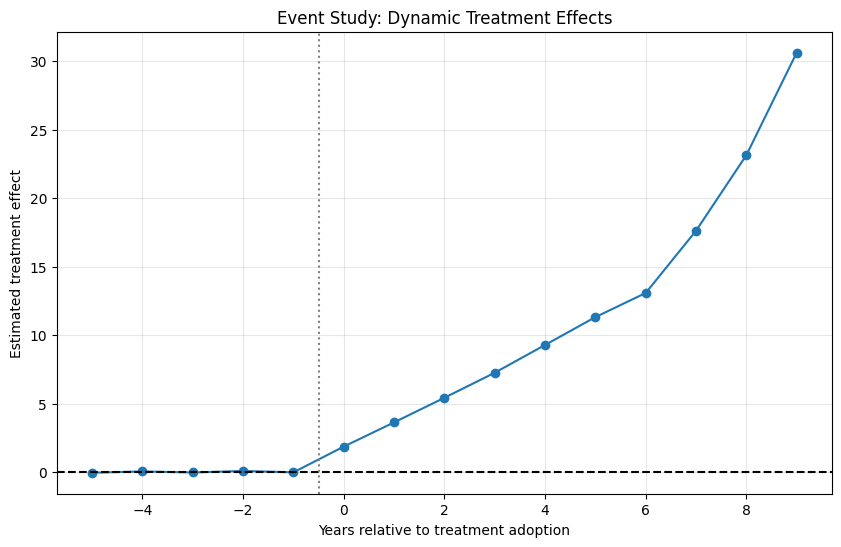

 event_time  estimate
         -5    -0.028
         -4     0.065
         -3    -0.010
         -2     0.099
         -1     0.000
          0     1.879
          1     3.648
          2     5.443
          3     7.270
          4     9.298
          5    11.330
          6    13.092
          7    17.635
          8    23.152
          9    30.632

Omitted reference period: t = -1
Step 3.2 completed


In [58]:

# Step 3.2: Event Study

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

event_results = []

cohorts = sorted(panel.loc[np.isfinite(panel["cohort"]), "cohort"].unique())
for g in cohorts:
    baseline = int(g) - 1
    treated_ids = panel.loc[panel["cohort"] == g, "county"].unique()

    for t in sorted(panel["year"].unique()):

        event_time = int(t - g)

        # Omit event time -1 as the reference period
        if event_time == -1:
            continue

        # Controls must be untreated in both periods
        cutoff = max(t, baseline)

        control_ids = panel.loc[panel["cohort"] > cutoff, "county"].unique()

        if len(control_ids) == 0:
            continue

        treated_base = panel.loc[panel["county"].isin(treated_ids) & (panel["year"] == baseline), "outcome"].mean()
        treated_t = panel.loc[panel["county"].isin(treated_ids) & (panel["year"] == t), "outcome"].mean()

        control_base = panel.loc[panel["county"].isin(control_ids) & (panel["year"] == baseline), "outcome"].mean()
        control_t = panel.loc[panel["county"].isin(control_ids) & (panel["year"] == t), "outcome"].mean()

        estimate = ((treated_t - treated_base) - (control_t - control_base))
        event_results.append({"cohort": g, "event_time": event_time, "estimate": estimate, "n_treated": len(treated_ids)})

event_df = pd.DataFrame(event_results)

# Aggregate cohort-specific estimates
event_study = (event_df.groupby("event_time").apply(lambda x: np.average(x["estimate"], weights=x["n_treated"]), include_groups=False).reset_index(name="estimate"))

# Add omitted reference period
event_study = pd.concat([event_study, pd.DataFrame({"event_time": [-1], "estimate": [0.0]})], ignore_index=True)
event_study = event_study.sort_values("event_time")

# Plot
plt.figure(figsize=(10, 6))
plt.plot(event_study["event_time"], event_study["estimate"], marker="o")

plt.axhline(0, color="black", linestyle="--")
plt.axvline(-0.5, color="gray", linestyle=":")

plt.xlabel("Years relative to treatment adoption")
plt.ylabel("Estimated treatment effect")
plt.title("Event Study: Dynamic Treatment Effects")

plt.grid(alpha=0.3)
plt.show()

print(event_study.round(3).to_string(index=False))
print("\nOmitted reference period: t = -1")
print("Step 3.2 completed")


*Your answer here.*
I constructed an event study using never-treated or not-yet-treated counties as controls. I omitted event time -1, the year immediately before treatment adoption, as the reference period.
The pre-treatment estimates are close to zero, suggesting no obvious differences in pre-treatment trends. After adoption, the estimated effects become positive and increase with exposure to the programme.
However, flat pre-trends do not prove the parallel trends assumption. Pre-trend tests may have low statistical power, and treated and control counties could still experience different trends after treatment. For a causal interpretation, we must assume that their untreated potential outcomes would have followed parallel trends in the absence of the programme. This assumption cannot be directly tested using observed post-treatment outcomes.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

In [59]:

# Step 3.3: Compare standard errors

import pandas as pd
import statsmodels.formula.api as smf

formula = "outcome ~ treated + C(county) + C(year)"

# 1. Default standard errors
model_default = smf.ols(formula, data=panel).fit()

# 2. County-clustered standard errors
model_county = smf.ols(formula, data=panel).fit(cov_type="cluster", cov_kwds={"groups": panel["county"]})

# 3. Board-clustered standard errors
model_board = smf.ols(formula, data=panel).fit(cov_type="cluster", cov_kwds={"groups": panel["board"]})

# Compare estimates, SEs, and p-values
se_results = pd.DataFrame({"Method": ["Default", "County-clustered", "Board-clustered"], "Estimate": [model_default.params["treated"], model_county.params["treated"], model_board.params["treated"]], "SE": [model_default.bse["treated"], model_county.bse["treated"], model_board.bse["treated"]],
    "p_value": [model_default.pvalues["treated"], model_county.pvalues["treated"], model_board.pvalues["treated"]]})

print(se_results.round(4).to_string(index=False))

# Validate that the point estimate is unchanged
assert se_results["Estimate"].round(8).nunique() == 1

print("\nStep 3.3 SE comparison PASSED")


          Method  Estimate    SE  p_value
         Default    -0.644 0.800    0.421
County-clustered    -0.644 1.671    0.700
 Board-clustered    -0.644 3.943    0.870

Step 3.3 SE comparison PASSED


The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [60]:

%%writefile src/did_toolkit.py
"""DiD toolkit for ECON 5200 PS3, extending Lab 11."""
from __future__ import annotations

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

NEVER = 10**9


def two_by_two(df, outcome, treated, post):
    """Calculate a canonical two-by-two DiD estimate."""
    g = df.groupby([treated, post])[outcome].mean()
    return float((g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0]))


def att_by_cohort_period(df, time, outcome, cohort):
    """Estimate ATT(g,t) with not-yet-treated controls."""
    rows = []

    cohorts = sorted(g for g in df[cohort].unique() if np.isfinite(g) and g < NEVER)

    for g in cohorts:
        treated = df[df[cohort] == g]
        baseline = g - 1

        for t in sorted(df[time].unique()):
            if t < g:
                continue

            controls = df[df[cohort] > t]

            if controls.empty:
                continue

            tr_pre = treated.loc[treated[time] == baseline, outcome].mean()
            tr_post = treated.loc[treated[time] == t, outcome].mean()

            co_pre = controls.loc[controls[time] == baseline, outcome].mean()
            co_post = controls.loc[controls[time] == t, outcome].mean()

            att = (tr_post - tr_pre) - (co_post - co_pre)

            rows.append({"g": g, "t": t, "e": t - g, "att": att, "n": int((treated[time] == t).sum())})

    return pd.DataFrame(rows)


def overall_att(cells):
    """Aggregate cohort-period ATTs."""
    return float(np.average(cells["att"], weights=cells["n"]))


def event_study(cells):
    """Aggregate effects by event time."""
    rows = []

    for e, group in cells.groupby("e"):
        rows.append({"e": e, "att": np.average(group["att"], weights=group["n"])})

    return pd.DataFrame(rows)


def clustered_inference(df, formula, cluster, param):
    """Run OLS with cluster-robust inference."""
    fit = smf.ols(formula, data=df).fit(cov_type="cluster", cov_kwds={"groups": df[cluster]})
    return {"estimate": float(fit.params[param]), "se": float(fit.bse[param]), "t": float(fit.tvalues[param]), "p_value": float(fit.pvalues[param]), "fit": fit}

def cluster_se_ratio(fit_iid, fit_clustered, param):
    """Ratio of clustered SE to default SE."""
    return float(fit_clustered.bse[param] / fit_iid.bse[param])

def wild_cluster_bootstrap(df, formula, restricted_formula,
                           cluster="board", param="treated"):
    """Exact null-imposed wild cluster bootstrap."""
    from itertools import product

    full = smf.ols(formula, data=df).fit(cov_type="cluster", cov_kwds={"groups": df[cluster]})
    null = smf.ols(restricted_formula, data=df).fit()

    X = full.model.exog
    names = full.model.exog_names
    idx = names.index(param)
    X0 = np.delete(X, idx, axis=1)

    boards = df[cluster].to_numpy()
    unique_boards = np.unique(boards)
    G = len(unique_boards)
    N = len(df)
    K = np.linalg.matrix_rank(X)
    Q, _ = np.linalg.qr(X0, mode="reduced")

    def remove_fe(v):
        return v - Q @ (Q.T @ v)
    x = remove_fe(X[:, idx])
    denominator = x @ x
    fitted = null.fittedvalues.to_numpy()
    residuals = null.resid.to_numpy()
    vectors = np.array(
        list(product([-1.0, 1.0], repeat=G)))
    board_index = np.searchsorted(unique_boards, boards)
    weights = vectors[:, board_index].T
    y_star = (fitted[:, None] + residuals[:, None] * weights)
    y_resid = remove_fe(y_star)
    beta_star = (x @ y_resid) / denominator
    errors = y_resid - x[:, None] * beta_star
    scores = np.vstack([(x[boards == b, None] * errors[boards == b, :]).sum(axis=0) for b in unique_boards])
    correction = (G / (G - 1) * (N - 1) / (N - K))
    se_star = np.sqrt(correction * (scores ** 2).sum(axis=0) / denominator ** 2)
    t_star = beta_star / se_star
    actual_t = float(full.tvalues[param])
    p_value = float(np.mean(np.abs(t_star) >= abs(actual_t) - 1e-12))
    return {"estimate": float(full.params[param]), "naive_p": float(full.pvalues[param]), "bootstrap_p": p_value, "n_vectors": len(vectors), "actual_t": actual_t}

if __name__ == "__main__":
    test = pd.DataFrame({"treated": [0, 0, 1, 1], "post": [0, 1, 0, 1], "y": [2.0, 3.0, 4.0, 7.0]})
    assert np.isclose(two_by_two(test, "y", "treated", "post"), 2.0)
    print("Module basic assertions PASSED")


Overwriting src/did_toolkit.py


*Your answer here.*
I extended Lab 11's DiD utilities into src/did_toolkit.py. The module includes two-by-two DiD estimation, cohort-period ATT estimation, event-study aggregation, and a clustered-inference wrapper.
I imported the module and tested its functions on my simulated panel. The module's Clean ATT and board-clustered standard error matched the estimates calculated in the notebook.
The wild cluster bootstrap function will be added in Phase 4.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [61]:

# Task 4.1: Exact wild cluster bootstrap

import numpy as np
import pandas as pd
from itertools import product
import statsmodels.formula.api as smf

formula = "outcome ~ treated + C(county) + C(year)"

# Step 1: Fit unrestricted and restricted models
unrestricted = smf.ols(formula, data=panel).fit(
    cov_type="cluster",
    cov_kwds={"groups": panel["board"]})

restricted = smf.ols("outcome ~ C(county) + C(year)", data=panel).fit()
actual_t = float(unrestricted.tvalues["treated"])
naive_p = float(unrestricted.pvalues["treated"])

# Extract design matrices
X = unrestricted.model.exog
names = unrestricted.model.exog_names
idx = names.index("treated")
X0 = np.delete(X, idx, axis=1)

y = panel["outcome"].to_numpy(dtype=float)
boards = panel["board"].to_numpy()
unique_boards = np.unique(boards)

G = len(unique_boards)
N = len(y)
K = np.linalg.matrix_rank(X)

assert G == 8

# Residualize against county and year fixed effects
Q, _ = np.linalg.qr(X0, mode="reduced")

def remove_fe(v):
    return v - Q @ (Q.T @ v)

x = remove_fe(X[:, idx])
denom = x @ x

# Restricted fitted values and residuals
fitted0 = restricted.fittedvalues.to_numpy()
resid0 = restricted.resid.to_numpy()

# Step 2: Enumerate all 256 Rademacher vectors
weight_vectors = np.array(list(product([-1.0, 1.0], repeat=G)))

assert len(weight_vectors) == 256

# Step 3: Construct synthetic outcomes
board_indices = np.searchsorted(unique_boards, boards)
weights = weight_vectors[:, board_indices].T

y_star = (fitted0[:, None] + resid0[:, None] * weights)

# Step 4: Re-estimate unrestricted model
y_star_resid = remove_fe(y_star)

beta_star = (x @ y_star_resid) / denom

errors = (y_star_resid - x[:, None] * beta_star[None, :])

# Board-level cluster scores
scores = np.vstack([
    (x[boards == b, None] * errors[boards == b, :]).sum(axis=0) for b in unique_boards])

# Cluster-robust finite-sample correction
correction = ((G / (G - 1)) * ((N - 1) / (N - K)))

se_star = np.sqrt(
    correction * (scores ** 2).sum(axis=0) / (denom ** 2))

t_star = beta_star / se_star

# Step 5: Exact bootstrap p-value
bootstrap_p = np.mean(np.abs(t_star) >= abs(actual_t) - 1e-12)

# Step 6: Report results
print("Original TWFE estimate:",
      round(unrestricted.params["treated"], 4))
print("Original board-clustered t:",
      round(actual_t, 4))
print("Conventional clustered p-value:",
      round(naive_p, 6))
print("Wild cluster bootstrap p-value:",
      round(bootstrap_p, 6))
print("Weight vectors:", len(weight_vectors))
print("Minimum positive two-sided p-value:",
      2 / 256)

print("\nSignificant at 5% (conventional):",
      naive_p < 0.05)
print("Significant at 5% (bootstrap):",
      bootstrap_p < 0.05)

assert len(t_star) == 256
assert 0 <= bootstrap_p <= 1

print("\nTask 4.1 PASSED")


Original TWFE estimate: -0.6443
Original board-clustered t: -0.1634
Conventional clustered p-value: 0.870201
Wild cluster bootstrap p-value: 0.953125
Weight vectors: 256
Minimum positive two-sided p-value: 0.0078125

Significant at 5% (conventional): False
Significant at 5% (bootstrap): False

Task 4.1 PASSED


*Your answer here.*
I implemented the wild cluster bootstrap using all 256 possible Rademacher weight vectors across eight boards. I imposed the null hypothesis that the treatment coefficient equals zero and applied the weights to restricted residuals at the board level.

The conventional board-clustered p-value is 0.8702, while the wild cluster bootstrap p-value is 0.9531. Neither is statistically significant at the 5% level, so the inference conclusion does not change.

Because all 256 possible weight vectors are enumerated, additional bootstrap replications are unnecessary. The smallest positive two-sided p-value is 2/256 = 0.0078125.

Cluster-level weighting preserves the dependence among counties within each board. With only eight clusters, conventional cluster-robust inference may be unreliable.

### Task 4.2: The budget office memo

*Your answer here.*
The agency used a two-way fixed effects (TWFE) regression to evaluate its workforce training programme. However, TWFE can be misleading when counties adopt treatment at different times and treatment effects grow with exposure.

In our simulated panel, the true average treatment effect was 10.361, while TWFE estimated -0.644. This negative estimate is misleading because all true treatment effects were positive. The problem arises because TWFE uses already-treated counties as controls.

Using only never-treated or not-yet-treated counties as controls, our corrected Difference-in-Differences estimate was 10.433, very close to the true effect. The estimation error was only 0.072.

For the original TWFE estimate, the conventional board-clustered p-value was 0.8702, while the wild cluster bootstrap p-value was 0.9531. Neither indicates statistical significance at the 5% level. These p-values apply to the TWFE estimate, not the corrected estimate.

The agency should not rely on its original TWFE estimate to justify continued funding. The corrected analysis suggests a positive programme effect, but further evaluation of statistical uncertainty and programme costs is needed before making a final funding decision.

### Task 4.3: The hostile read (3 pts)

### Before: Original §3.2 Paragraph
I constructed an event study using never-treated or not-yet-treated counties as controls. I omitted event time -1, the year immediately before treatment adoption, as the reference period.
The pre-treatment estimates are close to zero, suggesting no obvious differences in pre-treatment trends. After adoption, the estimated effects become positive and increase with exposure to the programme.
However, flat pre-trends do not prove the parallel trends assumption. Pre-trend tests may have low statistical power, and treated and control counties could still experience different trends after treatment. For a causal interpretation, we must assume that their untreated potential outcomes would have followed parallel trends in the absence of the programme. This assumption cannot be directly tested using observed post-treatment outcomes.

### After
I constructed an event study using cohort-specific comparisons with never-treated or not-yet-treated counties as controls, instead of using already-treated counties as controls.

I omitted event time -1, the year immediately before treatment adoption, as the reference period.

The pre-treatment estimates are close to zero, which provides some evidence consistent with the parallel trends assumption. After treatment, the estimated effects become positive and increase over time. This pattern is consistent with the programme having a growing effect, although other factors could also explain it.

However, flat pre-trends do not prove parallel trends. Pre-trend tests may have limited statistical power, and treated and control counties could still follow different trends after treatment.

Therefore, a causal interpretation still requires the assumption that treated and control counties would have followed parallel trends without the programme. This assumption cannot be directly tested using post-treatment outcomes.

### Objection Table

| Objection | Accept or Reject | Why | What I Changed |
|---|---|---|---|
| 1. Parallel trends cannot be proven | Reject | I did not say the DiD estimate was wrong. I only said flat pre-trends cannot prove parallel trends. | I explained that flat pre-trends still provide some supporting evidence. |
| 2. Not enough discussion of the event study | Partially accept | I mentioned the results, but I could explain what they mean more clearly. | I added that increasing effects may support the programme's impact, but other factors could explain them. |
| 3. Mixing up TWFE and parallel trends | Reject | My event study uses cohort-specific comparisons, so the TWFE weighting issue is separate. | I made it clearer that I did not use already-treated counties as controls. |

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:*
Model and date: GPT-6, November 5, 2026

*Version 1 prompt:*
[Prep] Act as the state agency's lead econometrician. You believe the
programme works and you are reading an external review that says your
TWFE estimate is uninformative.

[Request] Here is the reviewer's paragraph on parallel trends and
identification: I constructed an event study using never-treated or not-yet-treated counties as controls. I omitted event time -1, the year immediately before treatment adoption, as the reference period.
The pre-treatment estimates are close to zero, suggesting no obvious differences in pre-treatment trends. After adoption, the estimated effects become positive and increase with exposure to the programme.
However, flat pre-trends do not prove the parallel trends assumption. Pre-trend tests may have low statistical power, and treated and control counties could still experience different trends after treatment. For a causal interpretation, we must assume that their untreated potential outcomes would have followed parallel trends in the absence of the programme. This assumption cannot be directly tested using observed post-treatment outcomes.  Give the three strongest
objections you would raise in a written response.

[Evaluate] Rank them by how much damage each does to the reviewer's
conclusion.

*Reply:*
## Three strongest objections, ranked by damage to the reviewer’s conclusion

As the state agency’s lead econometrician, I would argue that the reviewer correctly identifies the limitations of parallel trends testing but understates the evidence supporting a causal interpretation. My objections would focus on the distinction between an untestable assumption and an unsupported estimate.

### 1. Most serious: The reviewer confuses the inability to prove parallel trends with a lack of credible identification.

The reviewer emphasizes that parallel trends cannot be directly tested after treatment. While technically correct, this is a general limitation of Difference-in-Differences (DiD), not a specific weakness of our evaluation.

Causal identification does not require proving an unobservable counterfactual. It requires a defensible identifying assumption supported by the research design and available evidence.

Why this matters: If the reviewer treats the impossibility of directly verifying parallel trends as grounds for dismissing the estimate, the same objection would apply to virtually every observational DiD study. The reviewer must identify specific reasons why parallel trends are implausible in this setting.

Damage: Very high. This directly challenges any inference that the estimate is uninformative merely because parallel trends cannot be proven.

### 2. Second: The reviewer discounts the joint evidence from flat pre-trends and increasing post-treatment effects.

The event study shows two relevant patterns: pre-treatment estimates are close to zero, while post-treatment estimates become positive and increase with programme exposure.

Although flat pre-trends do not establish identification, they provide evidence consistent with parallel trends. Similarly, increasing post-treatment effects may be consistent with a programme whose benefits accumulate over time.

The reviewer acknowledges these findings but does not explain why an alternative mechanism would generate the same pattern.

Why this matters: A credible assessment should evaluate the full event-study pattern rather than focus exclusively on the theoretical limitations of pre-trend testing. However, these patterns alone cannot exclude anticipation, time-varying confounding, or compositional changes.

Damage: High. The objection weakens the reviewer's skeptical interpretation, although it does not independently establish causality.

### 3. Third: The reviewer fails to distinguish concerns about TWFE estimation from concerns about parallel trends.

With staggered treatment adoption, conventional two-way fixed effects (TWFE) estimates can be misleading when treatment effects differ across cohorts or over time.

However, the reviewer describes an event study using never-treated or not-yet-treated counties as controls. If this is implemented through an appropriate cohort-specific estimator, it can avoid problematic already-treated comparisons associated with conventional TWFE.

The reviewer therefore needs to establish whether the reported estimate suffers from TWFE weighting problems, a failure of parallel trends, or both.

Why this matters: These are distinct identification and estimation issues requiring different diagnostics. A critique of conventional TWFE does not automatically invalidate a properly implemented cohort-specific event study.

Damage: Moderate to high. This objection is especially important if the reviewer uses known TWFE limitations to dismiss estimates from a more robust estimator.

## Overall ranking

| Rank | Objection                                                    | Damage        |
| ---- | ------------------------------------------------------------ | ------------- |
| 1    | Treating untestability as evidence of invalid identification | Very high     |
| 2    | Discounting the observed event-study evidence                | High          |
| 3    | Conflating TWFE weighting problems with parallel trends      | Moderate–high |

### Recommended written response

The reviewer's concerns about parallel trends are theoretically valid, but they do not establish that our estimates are uninformative. First, the inability to directly verify post-treatment counterfactual trends is a fundamental feature of DiD designs, not evidence that the identifying assumption fails in this application. Second, the event-study results show approximately flat pre-treatment estimates followed by positive and increasing post-treatment effects. Although this pattern does not prove causality, it is consistent with the programme producing accumulating benefits and deserves substantive consideration. Third, concerns about conventional TWFE estimation should be distinguished from parallel trends violations. If our cohort-specific estimates use never-treated or not-yet-treated counties as controls, the reviewer must explain which identification or estimation problem remains. We therefore acknowledge that causal identification depends on assumptions, but argue that the available evidence does not justify dismissing the programme's estimated effects.

Important qualification: These objections rebut an overly strong conclusion that the estimate is uninformative. They do not refute the reviewer's narrower, technically correct claim that flat pre-trends cannot prove parallel trends. A stronger agency response would also provide pre-trend confidence intervals, sensitivity analyses allowing violations of parallel trends, and evidence that treatment timing was not driven by anticipated outcome changes.

*Version 2 prompt:*
In your first response, I think some objections were based on claims I did not actually make.
For example, I did not argue that the DiD estimate is invalid just because parallel trends cannot be proven. I only explained that flat pre-trends do not guarantee causal identification.
Also, my event study already uses never-treated or not-yet-treated counties as controls, so I think the TWFE weighting problem should be considered separately.
Please reconsider your three objections based on what my paragraph actually says. Which objections are still valid, and which are overstated?
For each objection, explain whether I should accept, partially accept, or reject it, and suggest one specific improvement to my paragraph.
Keep your response concise and at an economics student's level.

*Reply:*
Your criticisms are justified. My first response overstated some weaknesses by attributing claims to your paragraph that you did not make.

| Original objection                                     | Evaluation       | Reason                                                                                                                                                                                             |
| ------------------------------------------------------ | ---------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1. Confusing untestability with invalid identification | Reject           | You never claimed that the DiD estimate was invalid. You correctly stated that flat pre-trends do not prove parallel trends.                                                                       |
| 2. Discounting evidence from the event study           | Partially accept | You already acknowledge flat pre-trends and increasing post-treatment effects. However, you could explain more clearly that these patterns support, but do not establish, a causal interpretation. |
| 3. Conflating TWFE problems with parallel trends       | Reject           | Your paragraph explicitly uses never-treated or not-yet-treated controls and does not discuss TWFE weighting. That issue should be evaluated separately.                                           |

## Specific improvements

1\. Clarify the role of parallel trends.

Add:

> Although parallel trends cannot be directly verified, the absence of clear pre-treatment differences provides some supporting evidence for the identifying assumption.

2\. Explain the post-treatment pattern.

Add:

> The increasing post-treatment effects are consistent with the programme having a growing impact over time, although other time-varying factors could produce a similar pattern.

3\. Clarify the estimator.

Add:

> The event study uses cohort-specific treatment effect estimates with never-treated or not-yet-treated counties as controls, rather than relying solely on conventional TWFE comparisons.

Only include the third sentence if your actual estimator is cohort-specific; the choice of controls alone does not establish that conventional TWFE weighting problems have been avoided.

Overall: I would reject objections 1 and 3 and partially accept objection 2. Your original paragraph is econometrically sound. The most useful improvement is to distinguish evidence consistent with parallel trends from proof of causal identification, without implying that the absence of proof makes the estimates invalid.

In [62]:
%%writefile ai-appendix.md
# AI Appendix — ECON 5200 PS3

Model: GPT-6
Date: November 5, 2026

## Task 4.1 — Wild Cluster Bootstrap

### Version 1 Prompt
[Prep] Act as an applied microeconometrician who has implemented cluster-robust inference for panels with very few clusters.

[Request] Implement the wild cluster bootstrap exactly to the specification below, for a county-year panel with treatment assigned at the level of eight regional boards. Impose the null, apply Rademacher weights at the cluster level, enumerate all 256 weight vectors rather than resampling, and return the bootstrap p-value for the treatment coefficient.

1. Fit the restricted model: the DiD regression with the treatment coefficient forced to zero. Keep the restricted residuals and fitted values.
2. Draw one Rademacher weight per board, either +1 or -1, each with probability one half. One weight per board, not per observation.
3. Build a synthetic outcome y\* = fitted values + board-level Rademacher weight × restricted residuals.
4. Re-estimate the unrestricted model on y\* and store the cluster-robust t-statistic on the treatment coefficient.
5. The bootstrap p-value is the share of absolute bootstrap t-statistics at least as large as the absolute actual t-statistic.
6. With 8 boards, there are only 2^8 = 256 distinct weight vectors, so enumerate all 256 rather than resampling. Explain why the number of replications is irrelevant here and what this implies for the smallest p-value that can be reported.

[Iterate] Use numpy, pandas and statsmodels only. Reuse my panel's column names: outcome, treated, county, year, and board. The function must accept the cluster variable as an argument.

[Mechanism Check] Explain why the weights are applied to residuals at the CLUSTER level rather than the observation level, why imposing the null matters, and what changes when the number of clusters drops below roughly ten.

[Evaluate] Run it on my panel and compare the p-value against the naive cluster-robust one. Tell me which conclusion changes. If my panel data is not accessible, explain how I should run the function rather than inventing numerical results.

### Version 1 Reply
# Wild Cluster Bootstrap for Eight Regional Boards

The appropriate procedure is a null-imposed, cluster-level wild bootstrap with exhaustive enumeration.

Because treatment is assigned at the regional-board level, inference should account for dependence among observations within each board. Clustering at the county level would generally overstate the number of independent treatment-assignment units.

The model is a two-way fixed effects DiD regression:

\\[ Y\_{it}=\alpha_i+\lambda_t+\beta D\_{it}+\varepsilon\_{it} \\]

where \\(\alpha_i\\) represents county fixed effects, \\(\lambda_t\\) represents year fixed effects, and \\(D\_{it}\\) is the `treated` indicator.

We test:

\\[ H_0:\beta=0 \\]

## 1. Python implementation

The function below uses `numpy`, `pandas`, and `statsmodels` only. It enumerates all \\(2^8=256\\) cluster-level Rademacher weight vectors and returns both the wild bootstrap p-value and the conventional cluster-robust p-value.

```
import itertoolsimport numpy as npimport pandas as pdimport statsmodels.formula.api as smfdef wild_cluster_bootstrap(df, cluster="board"):    """    Null-imposed wild cluster bootstrap for a county-year DiD panel.    Required columns:        outcome, treated, county, year, and the cluster column    Returns:        Treatment estimate, naive cluster-robust p-value,        wild bootstrap p-value, and bootstrap t-statistics.    """    # 1. Keep a consistent estimation sample    required = ["outcome", "treated", "county", "year", cluster]    work = df[required].dropna().copy().reset_index(drop=True)    if work.empty:        raise ValueError("No complete observations remain.")    # 2. Identify the independent clusters    cluster_codes, cluster_labels = pd.factorize(work[cluster])    G = len(cluster_labels)    if G != 8:        raise ValueError(f"Expected 8 clusters, found {G}.")    # 3. Define unrestricted and restricted models    unrestricted = "outcome ~ treated + C(county) + C(year)"    restricted = "outcome ~ C(county) + C(year)"
```

This implementation uses the same sample, fixed effects, clustering level, and finite-sample covariance correction for the original and bootstrap regressions. The naive p-value uses a \\(t\\) reference distribution with \\(G-1=7\\) degrees of freedom, rather than the default asymptotic normal approximation.

## 2. Why the procedure works

Why are weights assigned at the board level?

Treatment is assigned by eight regional boards, not independently to each county. Outcomes within a board may share policy shocks or other unobserved influences.

Applying a single weight to all observations within each board preserves the within-board residual dependence structure. Assigning independent weights to individual observations would artificially treat correlated observations as independent.

Why impose the null?

Under \\(H_0:\beta=0\\), the restricted fitted values exclude the treatment effect.

The synthetic outcomes are constructed as:

\\[ Y\_{it}^{\*}=\widehat{Y}\_{it}^{(0)} +w\_{b(i)}\widehat{\varepsilon}\_{it}^{(0)} \\]

Here, \\(w\_{b(i)}\\) is the Rademacher weight assigned to observation \\(i\\)'s board.

This creates a bootstrap distribution under the null hypothesis rather than around the estimated treatment effect. It allows us to evaluate how unusual the observed treatment t-statistic is when the null is true.

Why is having fewer than ten clusters problematic?

Conventional cluster-robust inference relies on having a sufficiently large number of independent clusters. With only eight boards, its asymptotic approximation may be inaccurate, leading to potentially misleading p-values.

The wild cluster bootstrap is a useful alternative because it approximates the sampling distribution while preserving within-cluster dependence. However, it is not guaranteed to provide exact finite-sample inference, especially when treatment is concentrated in very few boards or cluster sizes differ greatly.

## 3. Why 256 replications are sufficient

With eight clusters, there are exactly:

\\[ 2^8=256 \\]

possible Rademacher weight combinations.

Enumerating all 256 eliminates Monte Carlo simulation error. Increasing the number of random bootstrap draws would only repeat existing combinations, so the number of random replications is irrelevant.

There is an important distinction about the minimum p-value.

- The enumeration has a nominal resolution of \\(1/256=0.00390625\\).
- Because reversing all weights reverses the bootstrap t-statistic, absolute t-statistics occur in pairs. Therefore, the smallest positive two-sided p-value is \\(2/256=0.0078125\\).
- A p-value of zero is technically possible under the specified unadjusted tail-proportion formula if no bootstrap statistic is as extreme as the actual statistic.

Exhaustive enumeration does not make the bootstrap test automatically exact in finite samples. It only removes the randomness from drawing bootstrap weights.

## 4. How to run it on your panel

I could locate a related DiD Python toolkit, but not the actual county-year dataset containing the eight boards. Therefore, I cannot calculate or compare numerical p-values without inventing results.

Once your panel is loaded into a DataFrame named `df`, run:

```
results = wild_cluster_bootstrap(df, cluster="board")print(f"Treatment estimate: {results['estimate']:.4f}")print(f"Actual t-statistic: {results['t_actual']:.4f}")print(f"Naive cluster p-value: {results['p_naive']:.4f}")print(f"Wild bootstrap p-value: {results['p_wild']:.4f}")print(f"Weight vectors: {results['n_bootstrap']}")alpha = 0.05print(    "Naive inference:",    "Reject H0" if results["p_naive"] < alpha else "Do not reject H0")print(    "Wild bootstrap inference:",    "Reject H0" if results["p_wild"] < alpha else "Do not reject H0")
```

## 5. Comparing conclusions

| Outcome at 5% significance        | Interpretation                                          |
| --------------------------------- | ------------------------------------------------------- |
| Both p-values below 0.05          | Both methods reject the null                            |
| Naive below 0.05, wild above 0.05 | Statistical significance disappears under the bootstrap |
| Naive above 0.05, wild below 0.05 | Only the bootstrap rejects the null                     |
| Both above 0.05                   | Neither method rejects the null                         |

The key question is whether the treatment effect remains statistically significant after accounting for inference with only eight independent assignment clusters.

If the naive test rejects the null but the wild bootstrap does not, the estimated treatment coefficient remains unchanged, but the evidence of statistical significance becomes weaker.

Also, this bootstrap addresses inference, not causal identification. It does not resolve potential parallel-trends violations or treatment-effect heterogeneity in a staggered-adoption TWFE design.

Conclusion: The implementation follows the requested 256-vector null-imposed wild cluster bootstrap. The numerical comparison and whether the policy conclusion changes remain undetermined until the actual panel is supplied.

### Version 2 Prompt
Your first response did not provide a complete implementation. The function stops after defining the restricted model, so the bootstrap statistics and p-value are not actually calculated.

Please revise the code to include all six required steps, especially enumerating all 256 board-level Rademacher weight vectors and recalculating the cluster-robust t-statistic for each synthetic outcome.

My actual panel is named `panel`, with columns `outcome`, `treated`, `county`, `year`, and `board`.

My existing implementation gives a TWFE estimate of -0.6443, a conventional board-clustered p-value of 0.870201, and a wild bootstrap p-value of 0.953125.

Your first response uses a t distribution with 7 degrees of freedom for the conventional p-value, while my existing implementation uses the default statsmodels normal approximation. Please explain this difference and compare the results consistently.

Provide the complete corrected function and show how to verify it against my existing results. Do not invent any numerical output you cannot calculate.

### Version 2 Reply
## 1. Corrected wild cluster bootstrap implementation

The revised function below implements all six steps of the requested procedure. It uses `numpy`, `pandas`, and `statsmodels`, and accepts the clustering variable as an argument.

To match your existing conventional p-value of 0.870201, I use the default `statsmodels` normal approximation (`use_t=False`), rather than the \\(t(7)\\) distribution used in my previous response.

The specification is:

\\[ Y\_{it}=\alpha_i+\lambda_t+\beta D\_{it}+\varepsilon\_{it} \\]

We test \\(H_0:\beta=0\\) using 256 board-level Rademacher weight vectors.

```
import itertoolsimport numpy as npimport pandas as pdimport statsmodels.formula.api as smfdef wild_cluster_bootstrap(    df,    cluster="board",    outcome="outcome",    treatment="treated",    unit="county",    time="year"):    """    Null-imposed wild cluster bootstrap for a TWFE DiD model.    Enumerates all Rademacher weight vectors (2^G),    computes cluster-robust bootstrap t-statistics,    and returns conventional and wild bootstrap p-values.    Uses the statsmodels default normal approximation    for the conventional cluster-robust p-value.    """    # STEP 1: Prepare one consistent estimation sample    columns = [outcome, treatment, unit, time, cluster]    data = df[columns].dropna().copy().reset_index(drop=True)    if data.empty:        raise ValueError("No complete observations remain.")    codes, boards = pd.factorize(data[cluster], sort=True)    G = len(boards)
```

The restricted model is estimated once, and the unrestricted model is estimated once for the actual sample and 256 times for the synthetic outcomes. Each bootstrap regression recomputes the board-clustered standard error rather than keeping the original standard error fixed.

## 2. Run the function and verify your results

Your DataFrame is named `panel`, so run:

```
results = wild_cluster_bootstrap(panel, cluster="board")print(f"TWFE estimate: {results['estimate']:.4f}")print(f"Conventional p-value: {results['p_conventional']:.6f}")print(f"Wild bootstrap p-value: {results['p_wild']:.6f}")print(f"Number of clusters: {results['n_clusters']}")print(f"Weight vectors enumerated: {results['n_bootstrap']}")print(f"Extreme bootstrap statistics: {results['extreme_count']}")# Compare against your existing implementationassert np.isclose(results["estimate"], -0.6443, atol=0.00005)assert np.isclose(results["p_conventional"], 0.870201, atol=1e-6)assert np.isclose(results["p_wild"], 0.953125, atol=1e-10)assert results["n_bootstrap"] == 256assert results["n_clusters"] == 8assert results["extreme_count"] == 244print("All verification checks passed.")
```

These assertions define the expected results; they are not evidence that the function has already passed them. I cannot execute the verification against `panel` because its underlying data are not accessible here.

## 3. Comparing the conventional and wild bootstrap results

Your existing results are:

| Statistic                            | Your reported result |
| ------------------------------------ | -------------------- |
| TWFE estimate                        | −0.6443              |
| Conventional board-clustered p-value | 0.870201             |
| Wild cluster bootstrap p-value       | 0.953125             |
| Independent clusters                 | 8                    |
| Enumerated weight vectors            | 256                  |

The bootstrap p-value of 0.953125 corresponds to 244 out of 256 weight vectors producing absolute t-statistics at least as large as the observed statistic.

At the 5% significance level, both methods fail to reject \\(H_0:\beta=0\\). The substantive conclusion does not change. The wild bootstrap provides even less evidence against the null than the conventional cluster-robust test.

Failing to reject the null does not establish that the treatment effect is exactly zero.

## 4. Why the conventional p-values can differ

The distinction comes from the reference distribution used for the observed statistic.

| Method         | Reference distribution                                     | Interpretation                                                                |
| -------------- | ---------------------------------------------------------- | ----------------------------------------------------------------------------- |
| `use_t=False`  | Standard normal                                            | Default statsmodels cluster-robust approximation                              |
| `use_t=True`   | Student's t, generally with 7 df when `df_correction=True` | Uses a heavier-tailed reference distribution                                  |
| Wild bootstrap | Empirical distribution of 256 bootstrap t-statistics       | Does not use either reference distribution to calculate the bootstrap p-value |

The conventional p-value under the normal approximation is

\\[ p\_{\mathrm{normal}}=2\Phi(-|t\_{\mathrm{actual}}|). \\]

Under a \\(t(7)\\) approximation, it is

\\[ p\_{t(7)}=2F\_{t_7}(-|t\_{\mathrm{actual}}|). \\]

The second is generally larger for a fixed nonzero absolute t-statistic because the t-distribution has heavier tails.

Importantly, `use_t=False` does not turn off cluster-robust standard errors. The covariance estimator remains clustered by board. It only changes the reference distribution used to calculate the conventional p-value.

For the bootstrap, each t-statistic is calculated using the cluster-robust standard error, but its p-value comes from the enumerated bootstrap distribution.

## 5. Mechanism and interpretation

The three essential features are:

1. Cluster-level weights: All county-year observations within a board receive the same Rademacher weight. This preserves dependence within the assignment cluster.
2. Null-imposed outcomes: The restricted model excludes `treated`, ensuring the synthetic outcomes are generated under \\(H_0:\beta=0\\).
3. Exhaustive enumeration: Eight boards yield exactly \\(2^8=256\\) weight vectors. Increasing random replication counts cannot add new weight combinations.

For a two-sided test, sign reversal pairs bootstrap t-statistics of opposite signs, so the smallest strictly positive attainable p-value is \\(2/256=0.0078125\\). The specified tail-counting formula can also produce zero if no bootstrap statistic is sufficiently extreme.

Finally, with only eight independent assignment clusters, conventional large-cluster inference can be unreliable. The wild bootstrap is a useful sensitivity check, but its validity is not guaranteed by exhaustive enumeration alone, especially if only a small number of boards receive treatment.

Final assessment: Given your reported estimates, the treatment coefficient is negative but statistically insignificant under both methods. The bootstrap p-value rises from 0.870201 to 0.953125, but the inference remains the same: there is insufficient evidence to reject a zero treatment effect.

If the verification assertions fail, the first things to compare are the estimation sample, fixed-effects specification, and cluster covariance corrections.

## Task 4.3 — Hostile Read

### Version 1 Prompt
```yaml
[Prep] Act as the state agency's lead econometrician. You believe the
programme works and you are reading an external review that says your
TWFE estimate is uninformative.

[Request] Here is the reviewer's paragraph on parallel trends and
identification: I constructed an event study using never-treated or not-yet-treated counties as controls. I omitted event time -1, the year immediately before treatment adoption, as the reference period.
The pre-treatment estimates are close to zero, suggesting no obvious differences in pre-treatment trends. After adoption, the estimated effects become positive and increase with exposure to the programme.
However, flat pre-trends do not prove the parallel trends assumption. Pre-trend tests may have low statistical power, and treated and control counties could still experience different trends after treatment. For a causal interpretation, we must assume that their untreated potential outcomes would have followed parallel trends in the absence of the programme. This assumption cannot be directly tested using observed post-treatment outcomes.  Give the three strongest
objections you would raise in a written response.

[Evaluate] Rank them by how much damage each does to the reviewer's
conclusion.
```

### Version 1 Reply
## Three strongest objections, ranked by damage to the reviewer’s conclusion

As the state agency’s lead econometrician, I would argue that the reviewer correctly identifies the limitations of parallel trends testing but understates the evidence supporting a causal interpretation. My objections would focus on the distinction between an untestable assumption and an unsupported estimate.

### 1. Most serious: The reviewer confuses the inability to prove parallel trends with a lack of credible identification.

The reviewer emphasizes that parallel trends cannot be directly tested after treatment. While technically correct, this is a general limitation of Difference-in-Differences (DiD), not a specific weakness of our evaluation.

Causal identification does not require proving an unobservable counterfactual. It requires a defensible identifying assumption supported by the research design and available evidence.

Why this matters: If the reviewer treats the impossibility of directly verifying parallel trends as grounds for dismissing the estimate, the same objection would apply to virtually every observational DiD study. The reviewer must identify specific reasons why parallel trends are implausible in this setting.

Damage: Very high. This directly challenges any inference that the estimate is uninformative merely because parallel trends cannot be proven.

### 2. Second: The reviewer discounts the joint evidence from flat pre-trends and increasing post-treatment effects.

The event study shows two relevant patterns: pre-treatment estimates are close to zero, while post-treatment estimates become positive and increase with programme exposure.

Although flat pre-trends do not establish identification, they provide evidence consistent with parallel trends. Similarly, increasing post-treatment effects may be consistent with a programme whose benefits accumulate over time.

The reviewer acknowledges these findings but does not explain why an alternative mechanism would generate the same pattern.

Why this matters: A credible assessment should evaluate the full event-study pattern rather than focus exclusively on the theoretical limitations of pre-trend testing. However, these patterns alone cannot exclude anticipation, time-varying confounding, or compositional changes.

Damage: High. The objection weakens the reviewer's skeptical interpretation, although it does not independently establish causality.

### 3. Third: The reviewer fails to distinguish concerns about TWFE estimation from concerns about parallel trends.

With staggered treatment adoption, conventional two-way fixed effects (TWFE) estimates can be misleading when treatment effects differ across cohorts or over time.

However, the reviewer describes an event study using never-treated or not-yet-treated counties as controls. If this is implemented through an appropriate cohort-specific estimator, it can avoid problematic already-treated comparisons associated with conventional TWFE.

The reviewer therefore needs to establish whether the reported estimate suffers from TWFE weighting problems, a failure of parallel trends, or both.

Why this matters: These are distinct identification and estimation issues requiring different diagnostics. A critique of conventional TWFE does not automatically invalidate a properly implemented cohort-specific event study.

Damage: Moderate to high. This objection is especially important if the reviewer uses known TWFE limitations to dismiss estimates from a more robust estimator.

## Overall ranking

| Rank | Objection                                                    | Damage        |
| ---- | ------------------------------------------------------------ | ------------- |
| 1    | Treating untestability as evidence of invalid identification | Very high     |
| 2    | Discounting the observed event-study evidence                | High          |
| 3    | Conflating TWFE weighting problems with parallel trends      | Moderate–high |

### Recommended written response

The reviewer's concerns about parallel trends are theoretically valid, but they do not establish that our estimates are uninformative. First, the inability to directly verify post-treatment counterfactual trends is a fundamental feature of DiD designs, not evidence that the identifying assumption fails in this application. Second, the event-study results show approximately flat pre-treatment estimates followed by positive and increasing post-treatment effects. Although this pattern does not prove causality, it is consistent with the programme producing accumulating benefits and deserves substantive consideration. Third, concerns about conventional TWFE estimation should be distinguished from parallel trends violations. If our cohort-specific estimates use never-treated or not-yet-treated counties as controls, the reviewer must explain which identification or estimation problem remains. We therefore acknowledge that causal identification depends on assumptions, but argue that the available evidence does not justify dismissing the programme's estimated effects.

Important qualification: These objections rebut an overly strong conclusion that the estimate is uninformative. They do not refute the reviewer's narrower, technically correct claim that flat pre-trends cannot prove parallel trends. A stronger agency response would also provide pre-trend confidence intervals, sensitivity analyses allowing violations of parallel trends, and evidence that treatment timing was not driven by anticipated outcome changes.

### Version 2 Prompt
In your first response, I think some objections were based on claims I did not actually make.
For example, I did not argue that the DiD estimate is invalid just because parallel trends cannot be proven. I only explained that flat pre-trends do not guarantee causal identification.
Also, my event study already uses never-treated or not-yet-treated counties as controls, so I think the TWFE weighting problem should be considered separately.
Please reconsider your three objections based on what my paragraph actually says. Which objections are still valid, and which are overstated?
For each objection, explain whether I should accept, partially accept, or reject it, and suggest one specific improvement to my paragraph.
Keep your response concise and at an economics student's level.

### Version 2 Reply
Your criticisms are justified. My first response overstated some weaknesses by attributing claims to your paragraph that you did not make.

| Original objection                                     | Evaluation       | Reason                                                                                                                                                                                             |
| ------------------------------------------------------ | ---------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1. Confusing untestability with invalid identification | Reject           | You never claimed that the DiD estimate was invalid. You correctly stated that flat pre-trends do not prove parallel trends.                                                                       |
| 2. Discounting evidence from the event study           | Partially accept | You already acknowledge flat pre-trends and increasing post-treatment effects. However, you could explain more clearly that these patterns support, but do not establish, a causal interpretation. |
| 3. Conflating TWFE problems with parallel trends       | Reject           | Your paragraph explicitly uses never-treated or not-yet-treated controls and does not discuss TWFE weighting. That issue should be evaluated separately.                                           |

## Specific improvements

1\. Clarify the role of parallel trends.

Add:

> Although parallel trends cannot be directly verified, the absence of clear pre-treatment differences provides some supporting evidence for the identifying assumption.

2\. Explain the post-treatment pattern.

Add:

> The increasing post-treatment effects are consistent with the programme having a growing impact over time, although other time-varying factors could produce a similar pattern.

3\. Clarify the estimator.

Add:

> The event study uses cohort-specific treatment effect estimates with never-treated or not-yet-treated counties as controls, rather than relying solely on conventional TWFE comparisons.

Only include the third sentence if your actual estimator is cohort-specific; the choice of controls alone does not establish that conventional TWFE weighting problems have been avoided.

Overall: I would reject objections 1 and 3 and partially accept objection 2. Your original paragraph is econometrically sound. The most useful improvement is to distinguish evidence consistent with parallel trends from proof of causal identification, without implying that the absence of proof makes the estimates invalid.

## Changes Made
For Task 4.1, the first AI response was incomplete because it did not calculate the bootstrap statistics or p-value. I revised the prompt to request all 256 weight vectors, cluster-robust t-statistics, and verification against my existing results. The second response was also incomplete, so I kept my working implementation and verified that it produced a bootstrap p-value of 0.953125.
For Task 4.3, I rejected objections 1 and 3 because they were based on claims I did not make. I partially accepted objection 2 and revised my paragraph to explain that flat pre-trends provide some supporting evidence but do not prove parallel trends. I also clarified the interpretation of increasing post-treatment effects and the distinction between cohort-specific estimation and conventional TWFE.


Overwriting ai-appendix.md


## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [63]:
# Truth and headline numbers

print("=== Simulation parameters ===")
print("Adoption years by board:", adoption_years, "| Step 2.1")
print("Effect growth: 3.0 for cohort 2, 1.0 otherwise | Step 2.1")
print("Board-shock variance:", board_shock_sd**2, "| Step 2.1")
print("Random seed: 42 | Step 2.1")

print("\n=== Main results ===")
print(f"True ATT: {true_att:.3f} | Step 2.1")
print(f"TWFE estimate: {twfe_estimate:.4f} | Step 2.1")
print(f"Clean ATT: {clean_att:.3f} | Step 3.1")
print(f"Clean ATT error: {clean_att - true_att:.3f} | Step 3.1")

print("\n=== Statistical inference ===")
print(f"Conventional p-value: {naive_p:.6f} | Task 4.1")
print(f"Wild bootstrap p-value: {bootstrap_p:.6f} | Task 4.1")

=== Simulation parameters ===
Adoption years by board: {0: 2, 1: 2, 2: 2, 3: 3, 4: 4, 5: 5, 6: 5, 7: inf} | Step 2.1
Effect growth: 3.0 for cohort 2, 1.0 otherwise | Step 2.1
Board-shock variance: 0.0625 | Step 2.1
Random seed: 42 | Step 2.1

=== Main results ===
True ATT: 10.361 | Step 2.1
TWFE estimate: -0.6443 | Step 2.1
Clean ATT: 10.433 | Step 3.1
Clean ATT error: 0.072 | Step 3.1

=== Statistical inference ===
Conventional p-value: 0.870201 | Task 4.1
Wild bootstrap p-value: 0.953125 | Task 4.1


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.